<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and fixture](README.md)

# 01 · A complete FHIR search still needs reference and quantity checks

Fetching every page does not make every numeric Observation directly comparable. We will join synthetic Patient and Observation resources, keep unresolved references visible, inspect the raw quantity metadata that flattening does not expose, and normalize only the explicitly supported units.

**All resources are synthetic notebook fixtures. No patient records are used.** This is a data-shape and pagination walkthrough, not a clinical analysis or a FHIR profile-validation tool. One quantity is deliberately zero to show that numeric zero and an absent quantity remain different states; passing these SQL rules says nothing about clinical plausibility.

## Change page size without changing the dataset

`PAGE_SIZE` accepts **2** or **4** resources per Bundle page. The local fixture honors that size and returns explicit `next` links. The real worker follows them before local SQL analysis.

Change only **2 → 4** in the experiment. Predict fewer HTTP page requests with identical Patient/Observation identifiers, eligibility categories and converted values. `_count` controls a page, not the total number of matching resources. Restart the kernel and Run All after editing.

In [1]:
PAGE_SIZE = 2  # Accepted: 2 or 4 resources per page; experiment: 4

In [2]:
import hashlib
import json
import math
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from fixture_server import FixtureServer

assert type(PAGE_SIZE) is int and PAGE_SIZE in {2,4}
fixture_path=Path("synthetic_resources.json")
fixture_data=json.loads(fixture_path.read_text())
fixture_hash=hashlib.sha256(fixture_path.read_bytes()).hexdigest()
server=FixtureServer(fixture_path)
BASE_URL=server.url
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":125,"text.parse_math":False,"axes.spines.top":False,"axes.spines.right":False})
def prose(text):display(Markdown(text))
def finish(fig):
    fig.text(.01,.01,"Source: explicitly synthetic FHIR R4 notebook fixture · no patient data · technical inclusion rules, not clinical validation",fontsize=8,color="#555555")
    fig.tight_layout(rect=(0,.06,1,.98));plt.show()
con=haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-fhir/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-fhir/notebooks/pyproject.toml.

## Attach the native release and inspect server capabilities

The literal pinned release downloads and checksum-verifies the platform binary; no Go build or worker checkout is required. A small Python companion serves the committed synthetic resources on an ephemeral loopback port. It supports only the read-only fixture routes and does not forward requests elsewhere.

A FHIR [CapabilityStatement](https://hl7.org/fhir/R4/capabilitystatement.html) describes the advertised server surface. Here we verify the Patient and Observation search interactions before materializing either search.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'fhir' AS fhir (
    TYPE vgi,
    LOCATION 'github-auto://Query-farm/vgi-fhir@v0.4.0'
);

,Success


In [4]:
%%sql capabilities <<
SELECT resource_type,interactions
FROM fhir.main.fhir_capabilities('{{BASE_URL}}') ORDER BY resource_type;

In [5]:
display(capabilities)
assert set(capabilities.resource_type)=={"Patient","Observation"}
assert all("search-type" in x for x in capabilities.interactions)
prose(f"**SYNTHETIC FIXTURE** · SHA-256 `{fixture_hash}`. The local server advertises search for both resource types; no real clinical system or credentials are involved.")

,resource_type,interactions
0,Observation,[search-type]
1,Patient,[search-type]


**SYNTHETIC FIXTURE** · SHA-256 `e800fb04fe1b4d4f1ecaba0e1f5d5345c82d8b8fbd9d218492e09dfd16094f45`. The local server advertises search for both resource types; no real clinical system or credentials are involved.

## Follow every Bundle page and reconcile to the fixture inventory

The worker follows the server's `next` URL verbatim. Each search is materialized once; subsequent SQL reads local tables. This fixture is far below the worker's 1,000-resource search cap. For another server, reaching that cap or an empty page can stop the worker; a small `_count` is not proof that a real search is complete.

We can establish completeness here because the finite synthetic inventory is known independently. We check returned identifiers and the fixture server's page trace. This is stronger than merely asserting that a query returned some rows.

In [6]:
%%sql
CREATE TABLE patients AS
SELECT * FROM fhir.main.fhir_patients('{{BASE_URL}}',count:={{PAGE_SIZE}});
CREATE TABLE observations AS
SELECT * FROM fhir.main.fhir_observations('{{BASE_URL}}',count:={{PAGE_SIZE}});

,Count


In [7]:
%%sql source_coverage <<
SELECT 'Patient' AS resource_type,count(*) AS rows,count(DISTINCT id) AS unique_ids FROM patients
UNION ALL
SELECT 'Observation',count(*),count(DISTINCT id) FROM observations;

In [8]:
display(source_coverage)
trace=pd.DataFrame(server.requests)
request_summary=trace.groupby("resource",as_index=False).agg(requests=("rows","size"),returned_resources=("rows","sum"))
display(request_summary)
for kind,table in [("Patient","patients"),("Observation","observations")]:
    expected={r["id"] for r in fixture_data[kind]}
    actual=[r[0] for r in con.execute(f"SELECT id FROM {table}").fetchall()]
    assert len(actual)==len(expected) and set(actual)==expected
    requests=trace[trace.resource.eq(kind)]
    assert len(requests)==math.ceil(len(expected)/PAGE_SIZE)
    assert requests.rows.sum()==len(expected) and requests.offset.is_unique
assert source_coverage.rows.equals(source_coverage.unique_ids)
page_requests=int(trace.resource.ne("metadata").sum())
prose(f"At page size **{PAGE_SIZE}**, **{page_requests} search-page requests** returned **{int(source_coverage.rows.sum())} resources**. "
      "The separate metadata request is shown above. Every committed identifier arrived exactly once before joining or filtering.")

,resource_type,rows,unique_ids
0,Patient,4,4
1,Observation,12,12


,resource,requests,returned_resources
0,Observation,6,12
1,Patient,2,4
2,metadata,2,0


At page size **2**, **8 search-page requests** returned **16 resources**. The separate metadata request is shown above. Every committed identifier arrived exactly once before joining or filtering.

## Inspect raw quantity metadata and scope the reference join

The worker's flattened `value` is NULL when no numeric `valueQuantity` exists; it preserves the complete resource in `raw`. We recover the coding system, quantity system/code and comparator from that JSON. A display string such as `kg` alone is insufficient to establish a conversion.

FHIR [references](https://hl7.org/fhir/R4/references.html) can be relative, absolute, contained or logical. This example resolves **only exact `Patient/<id>` references** against its local Patient table. It does not strip an external base URL and assume the same identity. Absolute and missing-local references remain unresolved under this deliberately narrow rule.

Each fixture Observation has exactly one coding; a production mapping must decide how to handle multiple codings. The selected code/system pair is LOINC `29463-7`; other concepts are kept outside this demonstration's numeric subset.

In [9]:
%%sql
CREATE TABLE assessed AS
WITH expanded AS (
  SELECT o.*,json_extract_string(raw,'$.code.coding[0].system') AS coding_system,
         json_extract_string(raw,'$.valueQuantity.system') AS quantity_system,
         json_extract_string(raw,'$.valueQuantity.code') AS quantity_code,
         json_extract_string(raw,'$.valueQuantity.comparator') AS comparator
  FROM observations o
)
SELECT o.*,p.id AS patient_id,
       CASE WHEN p.id IS NULL THEN 'Unresolved subject'
            WHEN coding_system IS DISTINCT FROM 'http://loinc.org' OR code IS DISTINCT FROM '29463-7' THEN 'Other coding'
            WHEN status IS DISTINCT FROM 'final' THEN 'Outside final-status scope'
            WHEN value IS NULL THEN 'No numeric quantity'
            WHEN comparator IS NOT NULL THEN 'Comparator quantity'
            WHEN quantity_system IS DISTINCT FROM 'http://unitsofmeasure.org' OR quantity_code NOT IN ('kg','g') OR quantity_code IS NULL THEN 'Unsupported unit/system'
            ELSE 'Included exact quantity' END AS inclusion_reason
FROM expanded o LEFT JOIN patients p ON o.subject='Patient/'||p.id;

,Count


In [10]:
%%sql assessed <<
SELECT id,subject,patient_id,status,code,value,unit,quantity_system,quantity_code,comparator,inclusion_reason
FROM assessed ORDER BY id;

In [11]:
%%sql reasons <<
SELECT inclusion_reason,count(*) AS observations FROM assessed GROUP BY inclusion_reason ORDER BY inclusion_reason;

,id,subject,patient_id,status,code,value,unit,quantity_system,quantity_code,comparator,inclusion_reason
0,o01,Patient/p-a,p-a,final,29463-7,72.0,kg,http://unitsofmeasure.org,kg,None,Included exact quantity
1,o02,Patient/p-a,p-a,final,29463-7,72000.0,g,http://unitsofmeasure.org,g,None,Included exact quantity
2,o03,Patient/p-b,p-b,final,29463-7,0.0,kg,http://unitsofmeasure.org,kg,None,Included exact quantity
3,o04,Patient/p-b,p-b,final,29463-7,NaN,,None,None,None,No numeric quantity
4,o05,Patient/p-a,p-a,preliminary,29463-7,73.0,kg,http://unitsofmeasure.org,kg,None,Outside final-status scope
5,o06,Patient/p-a,p-a,final,8302-2,170.0,cm,http://unitsofmeasure.org,cm,None,Other coding
6,o07,Patient/missing,None,final,29463-7,80.0,kg,http://unitsofmeasure.org,kg,None,Unresolved subject
7,o08,Patient/p-b,p-b,final,29463-7,160.0,[lb_av],http://unitsofmeasure.org,[lb_av],None,Unsupported unit/system
8,o09,https://example.invalid/Patient/p-a,None,final,29463-7,74.0,kg,http://unitsofmeasure.org,kg,None,Unresolved subject
9,o10,Patient/p-a,p-a,final,29463-7,70.0,kg,http://unitsofmeasure.org,kg,<,Comparator quantity


,inclusion_reason,observations
0,Comparator quantity,1
1,Included exact quantity,3
2,No numeric quantity,1
3,Other coding,1
4,Outside final-status scope,2
5,Unresolved subject,2
6,Unsupported unit/system,2


The left join retains **12 observations**, including **2 unresolved subjects**. The reason categories are mutually exclusive and use the SQL CASE order: each row gets its first applicable exclusion. They describe this analysis policy, not intrinsic FHIR validity. Amended/corrected results, for example, would need an explicit policy rather than being silently treated as final here.

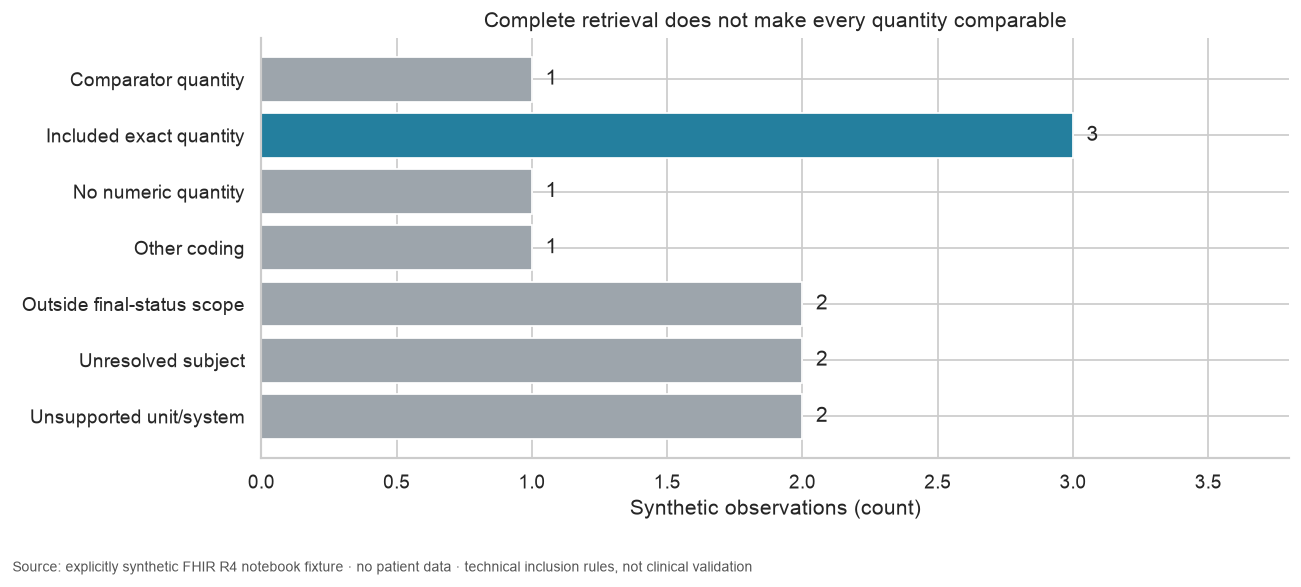

In [12]:
display(assessed)
display(reasons)
assert len(assessed)==len(fixture_data["Observation"]) and assessed.id.is_unique
assert reasons.observations.sum()==len(assessed)
assert all(len(r["code"]["coding"])==1 for r in fixture_data["Observation"])
for original in fixture_data["Observation"]:
    actual=assessed.set_index("id").loc[original["id"],"value"]
    expected=original.get("valueQuantity",{}).get("value")
    assert pd.isna(actual) if expected is None else actual==expected
prose(f"The left join retains **{len(assessed)} observations**, including **{int(assessed.patient_id.isna().sum())} unresolved subjects**. "
      "The reason categories are mutually exclusive and use the SQL CASE order: each row gets its first applicable exclusion. They describe this analysis policy, not intrinsic FHIR validity. Amended/corrected results, for example, would need an explicit policy rather than being silently treated as final here.")
fig,ax=plt.subplots(figsize=(10.5,4.8))
colors=["#247f9e" if x=="Included exact quantity" else "#9da5ac" for x in reasons.inclusion_reason]
ax.barh(reasons.inclusion_reason,reasons.observations,color=colors)
for i,x in enumerate(reasons.observations):ax.text(x+.05,i,str(x),va="center")
ax.set(xlabel="Synthetic observations (count)",title="Complete retrieval does not make every quantity comparable",xlim=(0,int(reasons.observations.max())+.8))
ax.invert_yaxis();finish(fig)

## Normalize only exact, supported quantities

The inclusion policy requires a resolved subject, the selected LOINC coding, status `final`, a numeric quantity, no comparator, and UCUM system/code `kg` or `g`. These are technical preconditions for this example, not clinical acceptance rules.

For that subset, **1,000 g = 1 kg**. The comparison retains original numbers and units beside normalized kilograms. A comparator such as `<70 kg` is not an exact 70 kg value and stays outside the conversion table. The deliberately zero-valued fixture remains numeric zero; no missing values are filled.

In [13]:
%%sql normalized <<
SELECT id,patient_id,value AS original_value,quantity_code AS original_unit,
       CASE WHEN quantity_code='g' THEN value/1000.0 ELSE value END AS normalized_kg
FROM assessed WHERE inclusion_reason='Included exact quantity' ORDER BY id;

,id,patient_id,original_value,original_unit,normalized_kg
0,o01,p-a,72.0,kg,72.0
1,o02,p-a,72000.0,g,72.0
2,o03,p-b,0.0,kg,0.0


**3 observations** meet this conversion policy, including **1 deliberately zero-valued fixture observation(s)**. The normalized table is independent of pagination. Analysis fingerprint: `bacac562340165028145ba9b4b8b465e4fa14b35b1155da79afe09ef739ab5cb`. No mean, diagnostic threshold or clinical conclusion is calculated.

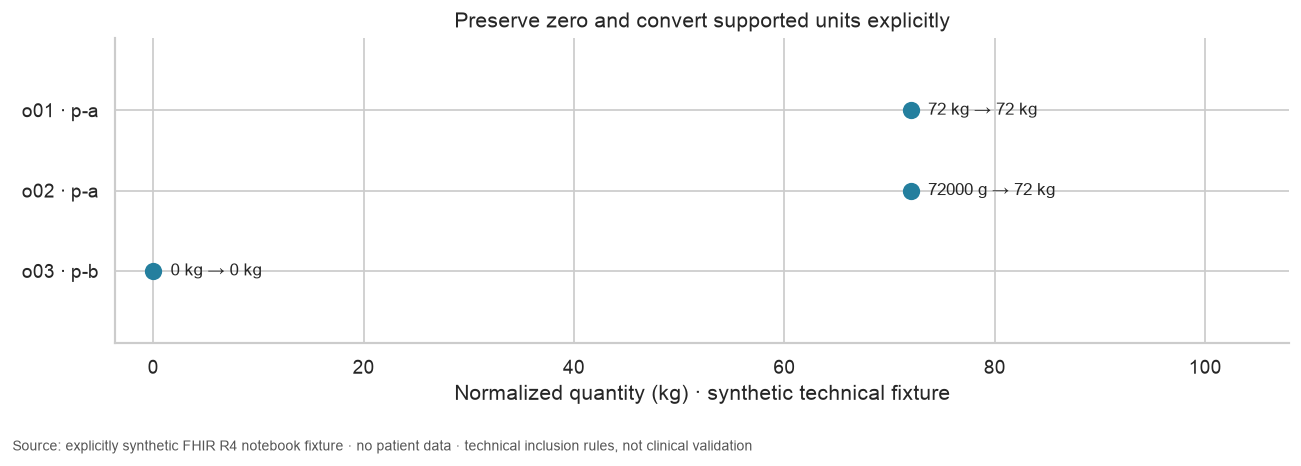

In [14]:
display(normalized)
assert not normalized.empty and normalized.id.is_unique
assert normalized.normalized_kg.notna().all()
assert np.allclose(normalized.normalized_kg,np.where(normalized.original_unit.eq("g"),normalized.original_value/1000,normalized.original_value))
assert normalized.original_value.eq(0).sum()==normalized.normalized_kg.eq(0).sum()
result_hash=hashlib.sha256(assessed.to_json(orient="records").encode()+normalized.to_json(orient="records").encode()).hexdigest()
prose(f"**{len(normalized)} observations** meet this conversion policy, including **{int(normalized.normalized_kg.eq(0).sum())} deliberately zero-valued fixture observation(s)**. "
      f"The normalized table is independent of pagination. Analysis fingerprint: `{result_hash}`. No mean, diagnostic threshold or clinical conclusion is calculated.")
fig,ax=plt.subplots(figsize=(10.5,3.8))
labels=[f"{r.id} · {r.patient_id}" for r in normalized.itertuples()]
ax.scatter(normalized.normalized_kg,labels,s=80,color="#247f9e")
for i,r in enumerate(normalized.itertuples()):ax.annotate(f"{r.original_value:g} {r.original_unit} → {r.normalized_kg:g} kg",(r.normalized_kg,i),xytext=(10,0),textcoords="offset points",va="center",fontsize=10)
span=max(float(normalized.normalized_kg.max()),1)
ax.set(xlabel="Normalized quantity (kg) · synthetic technical fixture",title="Preserve zero and convert supported units explicitly",xlim=(-.05*span,span*1.5))
ax.margins(y=.45);ax.invert_yaxis();finish(fig)

## One change to test

Change only **`PAGE_SIZE` from `2` to `4`** in a separate executed copy. Compare the fixture hash, resource identifiers, reason table, normalized values and analysis fingerprint: all should remain unchanged. The page trace should show fewer requests. Restore **2** afterward.

This harness deliberately supports a small subset of FHIR R4 search behavior and performs no clinical/profile validation. Real servers can impose limits, return different reference forms or multiple codings, and use other value types. Those require explicit handling before reusing the transformation. See the HL7 [Observation](https://hl7.org/fhir/R4/observation.html) and [search](https://hl7.org/fhir/R4/search.html) specifications for the surrounding resource and paging semantics.

In [15]:
con.execute("DETACH fhir")
con.close()
server.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and fixture](README.md)